# de Sitter geometry and curvature

*Symbolic verification.* $R=+12H^2$ in three charts with the convention of `docs/conventions.md`.

All computations call `desitter_qft`; see the matching `docs/` file for derivations.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from IPython.display import Image, display
from desitter_qft.plotting import apply_style; apply_style()
FIG = os.path.abspath(os.path.join('..', 'figures'))

In [2]:
from desitter_qft import backgrounds as bg
H = sp.Symbol('H', positive=True)
for name, f in [('flat (cosmic)', bg.flat_chart_metric_cosmic), ('flat (conformal)', bg.flat_chart_metric_conformal), ('static patch', bg.static_patch_metric)]:
    g, X = f(); print(f'{name:18s} R =', bg.ricci_scalar(g, X))
g, X = bg.flat_chart_metric_conformal()
print('R_mn - 3H^2 g_mn =', sp.simplify(bg.ricci_tensor(g, X) - 3*H**2*g) == sp.zeros(4, 4))

flat (cosmic)      R = 12*H**2
flat (conformal)   R = 12*H**2


static patch       R = 12*H**2
R_mn - 3H^2 g_mn = True


eta(t) = [-1.         -0.36787944 -0.00673795]  a(eta) = [  1.           2.71828183 148.4131591 ]  a(t) = [  1.           2.71828183 148.4131591 ]


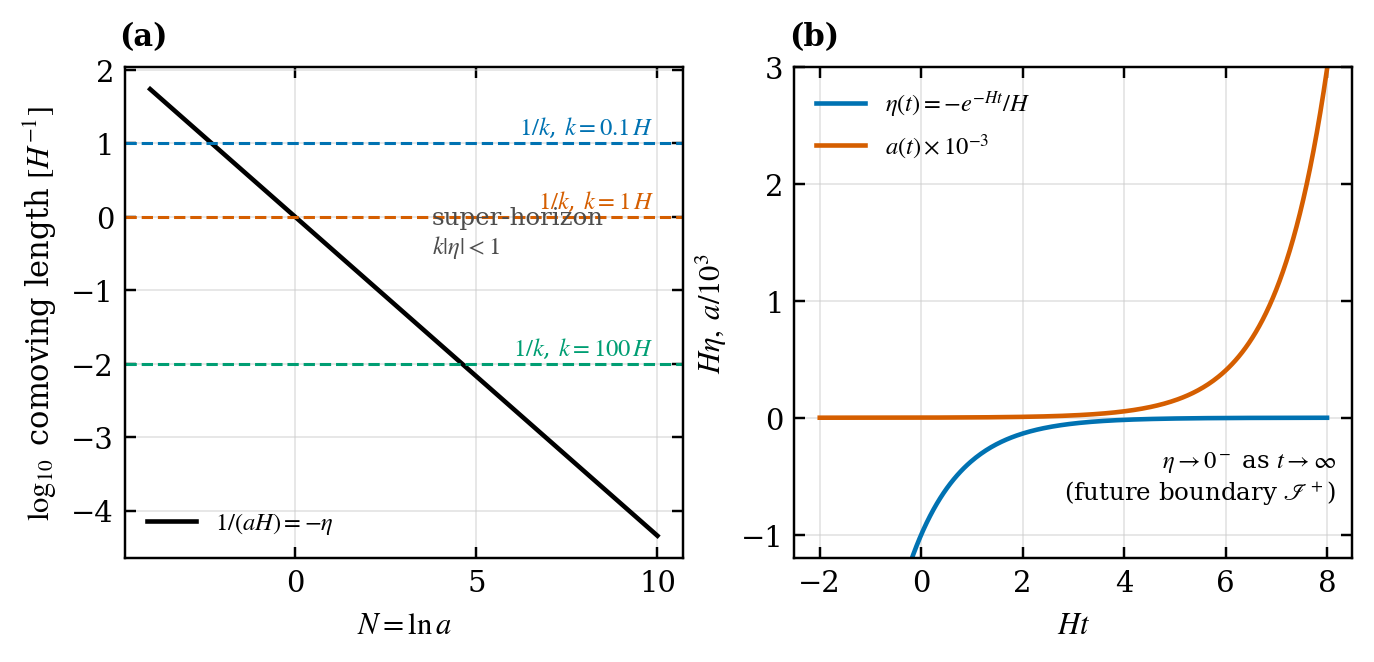

In [3]:
dS = bg.DeSitter(1.0)
t = np.array([0.0, 1.0, 5.0]); eta = dS.conformal_time(t)
print('eta(t) =', eta, ' a(eta) =', dS.scale_factor_conformal(eta), ' a(t) =', dS.scale_factor_cosmic(t))
display(Image(os.path.join(FIG, 'fig01_geometry_horizon.png')))